# Banking77 with TinyLlama 1.1B
## Apple Silicon: MPS LoRA

    **DSS workshop lab.** Fine-tune an ungated, approximately 1.1-billion-parameter chat model
    to return one of Banking77's 77 intent names. This notebook is self-contained and replaces
    the earlier synthetic-data script. No API key is required for these public sources.

    ## Goal
    Prepare real intent data, inspect response-only loss masks, train adapters, and compare
    generated labels with a base-model baseline. Record accuracy, macro-F1 over all 77 intents,
    and valid-label rate. No improvement or timing result is assumed.

    **Before the workshop:** install dependencies, download the model, then run a two-step smoke
    test in a new run directory. A short workshop run demonstrates the process and is not a
    converged Banking77 benchmark. First model download is roughly 2.2 GB for the weight payload.
    Internet access is required for initial setup.

    **Execution status:** preprocessing and tokenizer checks can run without a GPU. Actual
    accelerator training has not been executed in the authoring environment. GPU training and
    model-generated results have intentionally empty outputs until you run them.


## Setup
    Use Python 3.11 or 3.12 in a fresh notebook environment. Run this installation cell once,
    restart the kernel, then continue below. It installs into the active kernel. On CUDA,
    install a PyTorch build compatible with the runtime/driver first if necessary.


In [ ]:
%pip install "torch>=2.4" "transformers>=4.45,<6" "peft>=0.13,<1" accelerate pandas scikit-learn matplotlib sentencepiece tqdm


### 1. Imports and parameters
    Change these settings before running the lab. `TRAIN_PER_INTENT=20` keeps every intent
    represented in a short exercise. Short default runs may not see every selected example.
    Set `FULL_TRAINING=True` to train across the full cleaned training pool for `EPOCHS` epochs.
    The validation set always comes from the official training file.


In [1]:
import contextlib
import hashlib
import importlib.metadata
import json
import math
import os
from pathlib import Path
import platform
import random
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm.auto import tqdm
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # before transformers / torch import
from transformers import AutoTokenizer


In [2]:
MODEL_ID = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
MODEL_REVISION = "fe8a4ea1ffedaf415f4da2f062534de366a451e6"
METHOD = "lora"  # unquantized LoRA for this MPS lab
SEED = 42
FULL_TRAINING = False       # True uses the full cleaned train pool and epoch count below
EPOCHS = 1
TRAIN_PER_INTENT = 20       # None uses the full cleaned training pool
VAL_PER_INTENT = 2          # 154 development evaluation examples
VALIDATION_FRACTION = 0.10
MAX_STEPS = 30             # optimizer updates; use 2 for the first smoke test
GRAD_ACCUM = 2
RANK = 8
LEARNING_RATE = 2e-4
EVAL_EVERY = 20
MAX_NEW_TOKENS = 24
RUN_FINAL_TEST = False      # set True only after all configuration choices are frozen
RELOAD_FOR_INFERENCE = False
CACHE_DIR = Path("banking77_cache")
RUN_DIR = Path("runs/banking77_mps_" + METHOD + "_r" + str(RANK))
MPS_DTYPE = "float32"       # optional: "bfloat16" on a supported macOS/PyTorch stack
assert MAX_STEPS > 0 and GRAD_ACCUM > 0 and RANK > 0
assert 0 < VALIDATION_FRACTION < 1
assert LEARNING_RATE > 0 and EVAL_EVERY > 0
random.seed(SEED)
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})


### 2. Load the original Banking77 files
    The original data has **10,003 training queries**, **3,080 test queries** and **77 intents**.
    Load the pinned original CSVs and verify their SHA-256 hashes. This avoids the deprecated
    dataset-script loader in older copies of `PolyAI/banking77`.

    Attribution: BANKING77 © PolyAI Limited, **CC BY 4.0**. Casanueva et al. (2020),
    [Efficient Intent Detection with Dual Sentence Encoders](https://arxiv.org/abs/2003.04807).
    [Original source files](https://github.com/PolyAI-LDN/task-specific-datasets/tree/master/banking_data).


In [3]:
DATA_REVISION = "9d081458ff52e53cf7e848f414e6e9344e4e6696"
DATA_BASE = f"https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/{DATA_REVISION}/banking_data"
EXPECTED_SHA256 = {
    "train.csv": "b06e26ac675513959a63135f11b94ea7786ed02da65db93a5650d8838cbc664b",
    "test.csv": "d12d6e3bc4c3103966ae786dc435913c0c563dfa328f5a3646d0e62cfeeb474d",
    "categories.json": "53261da888122daf2d120d925458631d9619e15d82e56052e7a42e535ce32b63",
}
CACHE_DIR.mkdir(parents=True, exist_ok=True)
def verified_file(name):
    path = CACHE_DIR / name
    if not path.exists():
        with urllib.request.urlopen(f"{DATA_BASE}/{name}", timeout=60) as response:
            payload = response.read()
        if hashlib.sha256(payload).hexdigest() != EXPECTED_SHA256[name]:
            raise ValueError(f"Unexpected download hash: {name}")
        path.write_bytes(payload)
    if hashlib.sha256(path.read_bytes()).hexdigest() != EXPECTED_SHA256[name]:
        raise ValueError(f"Cached file changed: {path}. Remove it and rerun.")
    return path

raw_train = pd.read_csv(verified_file("train.csv"), keep_default_na=False)
raw_test = pd.read_csv(verified_file("test.csv"), keep_default_na=False)
LABELS = json.loads(verified_file("categories.json").read_text())
assert len(LABELS) == len(set(LABELS)) == 77
assert len(raw_train) == 10003 and len(raw_test) == 3080
assert set(raw_train.category) == set(raw_test.category) == set(LABELS)
assert raw_train.text.str.strip().ne("").all() and raw_test.text.str.strip().ne("").all()
print(f"Original files: {len(raw_train):,} train, {len(raw_test):,} test, {len(LABELS)} intents")
display(raw_train.head(3))


Original files: 10,003 train, 3,080 test, 77 intents


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival


### 3. Audit duplicates and create a validation split
    Normalize case and whitespace only for deduplication; preserve the original model inputs.
    Remove repeated training questions and training texts that also occur in the official test
    file. This is **text-only decontamination**, not tuning on test labels. Keep every official
    test row unchanged. The resulting experiment uses a cleaned training set, so report that
    preprocessing when comparing with published results.

    Split the remaining training pool within each intent, then take balanced workshop subsets.
    Persist source row indices so both notebooks can reproduce exactly the same data choices.


In [4]:
def normalized_text(text):
    return " ".join(text.casefold().split())

train_frame = raw_train.copy()
train_frame["source_row"] = np.arange(len(train_frame))
train_frame["text_key"] = train_frame.text.map(normalized_text)
test_keys = set(raw_test.text.map(normalized_text))
conflicts = train_frame.groupby("text_key").category.nunique()
assert conflicts.max() == 1, "Conflicting labels need review before splitting."
duplicate_count = int(train_frame.duplicated("text_key").sum())
train_frame = train_frame.drop_duplicates("text_key").copy()
overlap_count = int(train_frame.text_key.isin(test_keys).sum())
# Text-only decontamination. Official test labels and rows remain unchanged.
train_frame = train_frame.loc[~train_frame.text_key.isin(test_keys)].copy()

rng = np.random.default_rng(SEED)
train_parts, val_parts = [], []
for label in LABELS:
    group = train_frame.loc[train_frame.category.eq(label)]
    order = rng.permutation(len(group))
    n_val = max(2, int(round(len(group) * VALIDATION_FRACTION)))
    assert n_val < len(group)
    val_parts.append(group.iloc[order[:n_val]])
    train_parts.append(group.iloc[order[n_val:]])
train_pool = pd.concat(train_parts).reset_index(drop=True)
validation_pool = pd.concat(val_parts).reset_index(drop=True)

def balanced_subset(frame, per_intent, seed=SEED):
    if per_intent is None:
        return frame.sample(frac=1, random_state=seed).reset_index(drop=True)
    if per_intent < 1:
        raise ValueError("per_intent must be positive or None")
    groups = [frame.loc[frame.category.eq(label)].sample(
        n=min(per_intent, int(frame.category.eq(label).sum())), random_state=seed)
        for label in LABELS]
    return pd.concat(groups).sample(frac=1, random_state=seed).reset_index(drop=True)

train_data = balanced_subset(train_pool, None if FULL_TRAINING else TRAIN_PER_INTENT)
if FULL_TRAINING:
    MAX_STEPS = math.ceil(len(train_data) / GRAD_ACCUM) * EPOCHS
val_data = balanced_subset(validation_pool, VAL_PER_INTENT)
assert set(train_pool.text_key).isdisjoint(validation_pool.text_key)
assert set(train_pool.text_key).isdisjoint(test_keys)
assert set(validation_pool.text_key).isdisjoint(test_keys)
assert set(train_data.category) == set(val_data.category) == set(LABELS)
split_manifest = {
    "dataset_revision": DATA_REVISION, "seed": SEED,
    "normalization": "Unicode casefold and whitespace collapse",
    "duplicate_training_rows_removed": duplicate_count,
    "test_overlapping_training_texts_removed": overlap_count,
    "train_source_rows": train_data.source_row.astype(int).tolist(),
    "validation_source_rows": val_data.source_row.astype(int).tolist(),
    "official_test_rows": len(raw_test),
}
print(f"Removed {duplicate_count} repeated training texts and {overlap_count} train/test text overlaps.")
display(pd.DataFrame({
    "split": ["training pool", "validation pool", "workshop train", "workshop validation", "official test"],
    "rows": [len(train_pool), len(validation_pool), len(train_data), len(val_data), len(raw_test)],
    "purpose": ["training source", "tuning source", "short training run", "development evaluation", "final evaluation only"],
}))


Removed 4 repeated training texts and 7 train/test text overlaps.


,split,rows,purpose
0,training pool,8992,training source
1,validation pool,1000,tuning source
2,workshop train,1540,short training run
3,workshop validation,154,development evaluation
4,official test,3080,final evaluation only


### 4. Inspect class coverage
    The chart previews the 12 most frequent intents in the original training file. The workshop
    subsets below it must cover all 77 intents. This is a data check, not a model result.


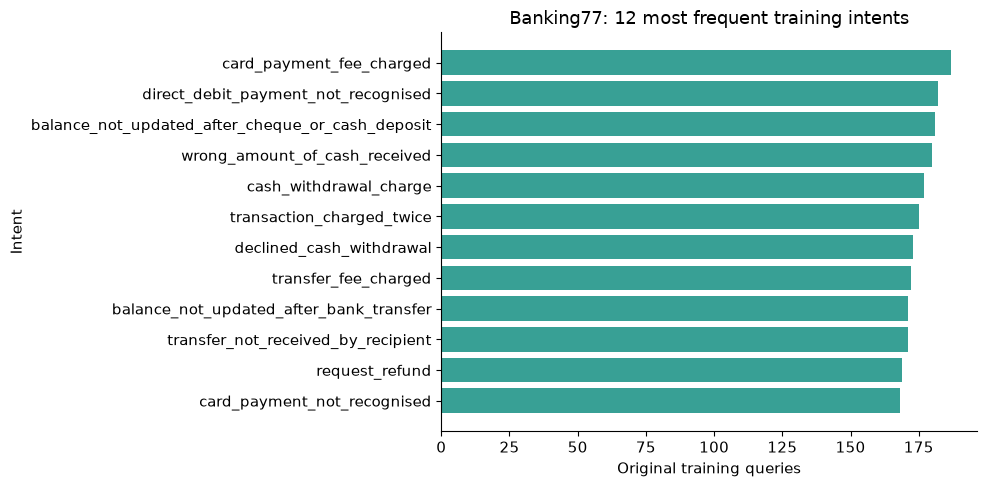

,train,validation
count,77.0,77.0
mean,20.0,2.0
std,0.0,0.0
min,20.0,2.0
25%,20.0,2.0
50%,20.0,2.0
75%,20.0,2.0
max,20.0,2.0


In [5]:
counts = raw_train.category.value_counts().nlargest(12).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(counts.index, counts.values, color="#38A095")
ax.set(title="Banking77: 12 most frequent training intents",
       xlabel="Original training queries", ylabel="Intent")
ax.set_xlim(left=0)
fig.tight_layout()
plt.show()
display(pd.DataFrame({"train": train_data.category.value_counts(),
                      "validation": val_data.category.value_counts()}).describe())


## Steps
    ### 5. Define the task and the assistant-only loss mask
    Both models see the identical list of valid intent names. The answer copies the upstream
    spelling exactly, including names such as `Refund_not_showing_up` and `reverted_card_payment?`.
    Do not lowercase labels or infer IDs from another dataset's ordering.

    Train only on assistant answer tokens and the final EOS token. Mask system, user and padding
    positions with `-100`. The code checks the token boundary and refuses silent truncation. It drops only trailing template whitespace after the final EOS.


In [6]:
# Preserve the upstream category spelling, punctuation and capitalization.
# The same full label catalog is visible to both the base and adapted model.
SYSTEM_PROMPT = (
    "Classify the banking customer's intent. Return exactly one category name "
    "from this list, copied verbatim. Do not explain.\n\n" + "\n".join(LABELS)
)
def prompt_messages(text):
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": str(text)}]

def encode_example(text, category, tokenizer, max_length=None):
    messages = prompt_messages(text)
    prompt_ids = tokenizer.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True, return_dict=True)["input_ids"]
    full_ids = tokenizer.apply_chat_template(
        messages + [{"role": "assistant", "content": category}],
        tokenize=True, add_generation_prompt=False, return_dict=True)["input_ids"]
    # TinyLlama renders a newline after EOS. Keep the answer ending, drop only
    # the trailing template whitespace so the supervised completion ends at EOS.
    final_eos = max((i for i, token in enumerate(full_ids)
                     if token == tokenizer.eos_token_id), default=-1)
    full_ids = full_ids[:final_eos + 1]
    if full_ids[:len(prompt_ids)] != prompt_ids:
        raise ValueError("Chat-template token boundary changed. Inspect the prefix before training.")
    if len(full_ids) <= len(prompt_ids) or full_ids[-1] != tokenizer.eos_token_id:
        raise ValueError("Completion or end-of-turn supervision is missing.")
    if max_length is not None and len(full_ids) > max_length:
        raise ValueError("Example exceeds the configured context. Increase it; never truncate targets silently.")
    pad = 0 if max_length is None else max_length - len(full_ids)
    return {
        "input_ids": full_ids + [tokenizer.pad_token_id] * pad,
        "attention_mask": [1] * len(full_ids) + [0] * pad,
        "labels": [-100] * len(prompt_ids) + full_ids[len(prompt_ids):] + [-100] * pad,
    }


### 6. Tokenize and verify one batch
    Load only the pinned tokenizer here. A complete 77-label catalog consumes context, so derive
    a fixed sequence length from the selected train/validation examples, rounded to 64 tokens.
    This is intentionally a generative classification lab. An encoder classifier or a dedicated
    classification head may be more efficient for production intent routing.


In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

unpadded_train = [encode_example(r.text, r.category, tokenizer)
                  for r in train_data.itertuples()]
unpadded_val = [encode_example(r.text, r.category, tokenizer)
                for r in val_data.itertuples()]
observed_max = max(len(row["input_ids"]) for row in unpadded_train + unpadded_val)
# Fixed training shapes limit graph-cache growth on MPS. Use the same rule on CUDA.
SEQUENCE_LENGTH = math.ceil(observed_max / 64) * 64
if SEQUENCE_LENGTH > 2048:
    raise ValueError("The complete prompt exceeds TinyLlama's 2,048-token context.")
encoded_train = [encode_example(r.text, r.category, tokenizer, SEQUENCE_LENGTH)
                 for r in train_data.itertuples()]
encoded_val = [encode_example(r.text, r.category, tokenizer, SEQUENCE_LENGTH)
               for r in val_data.itertuples()]
supervised_ids = [i for i in encoded_train[0]["labels"] if i != -100]
assert MAX_NEW_TOKENS >= max(len(tokenizer(label, add_special_tokens=False)["input_ids"]) + 1 for label in LABELS)
print("Fixed training sequence length:", SEQUENCE_LENGTH)
print("Supervised continuation:", repr(tokenizer.decode(supervised_ids)))
assert tokenizer.decode(supervised_ids).endswith(tokenizer.eos_token)
assert all(len(r["input_ids"]) == SEQUENCE_LENGTH for r in encoded_train)
assert all(any(i != -100 for i in r["labels"]) for r in encoded_train)
assert all(label == -100 for r in encoded_train
           for label, mask in zip(r["labels"], r["attention_mask"]) if mask == 0)


Fixed training sequence length: 832
Supervised continuation: 'automatic_top_up</s>'


### 7. Check Apple MPS and load the model
    This notebook uses ordinary LoRA with the standard PyTorch MPS backend. It has no CUDA or bitsandbytes dependency. Start with FP32 for compatibility; BF16 is optional after checking device support. The FP32 frozen weight payload alone is about 4.4 decimal GB, and activations and macOS require additional memory. There is no promise that an 8 GB Mac will fit this lab.

    A nonempty run directory stops execution to protect prior experiments. The model's runtime
    parameter count is printed, rather than assuming every architecture is exactly one billion.


In [ ]:
import torch
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
    raise FileExistsError(f"{RUN_DIR} is not empty. Choose a new RUN_DIR.")
RUN_DIR.mkdir(parents=True, exist_ok=True)
torch.manual_seed(SEED)

if not torch.backends.mps.is_available():
    raise RuntimeError("MPS unavailable. Use native arm64 Python and a compatible macOS/PyTorch installation.")
DEVICE = torch.device("mps")
torch.mps.manual_seed(SEED)
assert METHOD == "lora", "This notebook's training path is unquantized LoRA."
assert MPS_DTYPE in {"float32", "bfloat16"}
WEIGHT_DTYPE = getattr(torch, MPS_DTYPE)
probe = torch.ones((2, 2), device=DEVICE, dtype=WEIGHT_DTYPE, requires_grad=True)
(probe @ probe).float().sum().backward()  # BF16/device probe before loading weights
del probe
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, torch_dtype=WEIGHT_DTYPE,
    attn_implementation="sdpa").to(DEVICE)
def training_precision():
    return contextlib.nullcontext()  # explicit weight dtype; no CUDA AMP assumptions
scaler = torch.amp.GradScaler("cpu", enabled=False)
def synchronize():
    torch.mps.synchronize()
def prepare_memory_measurement():
    torch.mps.empty_cache()
def memory_snapshot():
    synchronize()
    return {"mps_" + name + "_GB": getattr(torch.mps, name)() / 1e9
            for name in ["current_allocated_memory", "driver_allocated_memory"]
            if hasattr(torch.mps, name)}
MEMORY_DEFINITION = "MPS memory snapshots at optimizer-step boundaries, NOT peaks. Current allocation covers tensors; driver allocation also includes allocator/Metal overhead."
print(platform.machine(), platform.mac_ver()[0], WEIGHT_DTYPE)


In [ ]:
model.config.use_cache = False
parameter_count = sum(p.numel() for p in model.parameters())
print(f"Model parameter objects: {parameter_count:,}")
print("Memory counters:", memory_snapshot())
# Quantized parameter objects do not necessarily expose the original dense count.
print("Model card dense parameter count: 1,100,048,384 (about 1.1B)")


### 8. Baseline evaluation on validation data
    Record the base-model outputs before attaching the adapter. Use deterministic greedy
    decoding. Strict accuracy counts verbose or malformed answers as errors. Macro-F1 fixes
    the label list to all 77 intents; invalid predictions receive ID `-1`, never a fuzzy match.


In [8]:
LABEL_TO_ID = {label: i for i, label in enumerate(LABELS)}

def summarize_predictions(frame):
    y_true = [LABEL_TO_ID[x] for x in frame.expected]
    # Invalid text stays an error, rather than being fuzzy-matched to a label.
    y_pred = [LABEL_TO_ID.get(x, -1) for x in frame.predicted]
    return {
        "n": len(frame),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1_77_intents": float(f1_score(
            y_true, y_pred, labels=list(range(77)), average="macro", zero_division=0)),
        "valid_label_rate": float(frame.predicted.isin(LABELS).mean()),
    }

def predict_frame(model, frame, description):
    was_training = model.training
    model.eval()
    records = []
    with torch.inference_mode():
        for row in tqdm(frame.itertuples(), total=len(frame), desc=description):
            inputs = tokenizer.apply_chat_template(
                prompt_messages(row.text), tokenize=True, add_generation_prompt=True,
                return_dict=True, return_tensors="pt")
            if inputs["input_ids"].shape[1] + MAX_NEW_TOKENS > 2048:
                raise ValueError("Inference prompt exceeds model context.")
            inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
            generated = model.generate(
                **inputs, do_sample=False, max_new_tokens=MAX_NEW_TOKENS,
                use_cache=True, pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id)
            new_tokens = generated[0, inputs["input_ids"].shape[1]:].cpu()
            prediction = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
            records.append({"text": row.text, "expected": row.category,
                            "predicted": prediction, "correct": prediction == row.category})
    model.train(was_training)
    result = pd.DataFrame(records)
    return result, summarize_predictions(result)

def validation_loss(model):
    was_training = model.training
    model.eval()
    nll_sum, token_count = 0.0, 0
    with torch.inference_mode():
        for row in encoded_val:
            batch = {k: torch.tensor([v], dtype=torch.long, device=DEVICE)
                     for k, v in row.items()}
            # Causal loss shifts labels by one position.
            n_tokens = int((batch["labels"][:, 1:] != -100).sum().item())
            loss = model(**batch).loss.float().item()
            nll_sum += loss * n_tokens
            token_count += n_tokens
    model.train(was_training)
    return nll_sum / token_count


In [ ]:
baseline_predictions, baseline_metrics = predict_frame(model, val_data, "Base: validation")
display(pd.DataFrame([baseline_metrics], index=["base validation"]))
display(baseline_predictions.head(5))


### 9. Attach LoRA and inspect trainable parameters
    Rank 8 with alpha 16 is a starting choice. Only `q_proj` and `v_proj` receive adapters.
    The CUDA QLoRA path prepares the quantized base before wrapping it. Both notebooks use
    gradient checkpointing with a microbatch of one. Gradient accumulation changes the
    effective batch without enlarging that microbatch.


In [ ]:
if METHOD == "qlora":
    model = prepare_model_for_kbit_training(model)
model = get_peft_model(model, LoraConfig(
    r=RANK, lora_alpha=2 * RANK, lora_dropout=0.05, bias="none",
    target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM"))
model.enable_input_require_grads()
model.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={"use_reentrant": False})
names = [name for name, parameter in model.named_parameters() if parameter.requires_grad]
assert names and all("lora_" in name for name in names), names
trainable_parameters = [p for p in model.parameters() if p.requires_grad]
# Keep optimizer-updated parameters in FP32, including when the frozen base is 16-bit.
for parameter in trainable_parameters:
    parameter.data = parameter.data.float()
model.print_trainable_parameters()
display(pd.DataFrame({"trainable_parameter": names}).head(8))
optimizer = torch.optim.AdamW(trainable_parameters, lr=LEARNING_RATE,
                             weight_decay=0.0, foreach=False)
print("Effective examples per update:", GRAD_ACCUM)


### 10. Train the adapter
    The loop averages response-only cross-entropy over microbatches. CUDA FP16 uses loss
    scaling; MPS does not borrow CUDA-specific AMP settings. Check finite loss and gradients,
    clip the gradient norm, and log validation loss periodically. The last checkpoint is saved;
    this lab does not silently choose the best test result.


In [ ]:
# Update only adapters. Keep the frozen backbone in the forward/backward graph.
model.train()
optimizer.zero_grad(set_to_none=True)
order = np.arange(len(encoded_train))
step_rng = np.random.default_rng(SEED)
step_rng.shuffle(order)
position = 0
history = []
prepare_memory_measurement()
synchronize()
start = time.perf_counter()

for step in tqdm(range(1, MAX_STEPS + 1), desc="Optimizer updates"):
    micro_losses = []
    for _ in range(GRAD_ACCUM):
        if position == len(order):
            step_rng.shuffle(order)
            position = 0
        row = encoded_train[int(order[position])]
        position += 1
        batch = {k: torch.tensor([v], dtype=torch.long, device=DEVICE)
                 for k, v in row.items()}
        with training_precision():
            loss = model(**batch).loss
        if not torch.isfinite(loss).item():
            raise RuntimeError("Non-finite loss. Try a lower LR or FP32 in a fresh run.")
        micro_losses.append(loss.detach().float().item())
        scaler.scale(loss / GRAD_ACCUM).backward()
        del batch, loss
    scaler.unscale_(optimizer)
    grad_norm = torch.nn.utils.clip_grad_norm_(
        trainable_parameters, 1.0, error_if_nonfinite=True, foreach=False)
    scaler.step(optimizer)
    scaler.update()
    optimizer.zero_grad(set_to_none=True)
    row = {"step": step, "train_loss": float(np.mean(micro_losses)),
           "grad_norm": float(grad_norm.detach().cpu()), **memory_snapshot()}
    if step % EVAL_EVERY == 0 or step == MAX_STEPS:
        row["validation_loss"] = validation_loss(model)
    history.append(row)
    if step == 1 or step % 10 == 0 or step == MAX_STEPS:
        tqdm.write(json.dumps(row))

synchronize()
training_seconds = time.perf_counter() - start
training_memory = memory_snapshot()
model.gradient_checkpointing_disable()
print(f"Training wall time: {training_seconds:.1f} s (includes validation and logging)")


### 11. Compare validation outcomes
    Rerun the identical validation prompts. Inspect errors before interpreting aggregate scores.
    A short run may fail to improve accuracy. Use these development results to choose the next
    experiment, then reserve the official test file for a single final assessment.


In [ ]:
adapted_predictions, adapted_metrics = predict_frame(model, val_data, "Adapter: validation")
validation_comparison = pd.DataFrame(
    [baseline_metrics, adapted_metrics], index=["base", "adapted"])
display(validation_comparison)
display(adapted_predictions.loc[~adapted_predictions.correct].head(10))


In [ ]:
logs = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(logs.step, logs.train_loss, color="#756A3D", label="Train microbatch mean")
validation_logs = logs.dropna(subset=["validation_loss"])
axes[0].plot(validation_logs.step, validation_logs.validation_loss, "o-",
             color="#38A095", label="Validation token-weighted")
axes[0].set(title="Response-only loss", xlabel="Optimizer step", ylabel="Cross-entropy")
axes[0].legend()
validation_comparison[["accuracy", "macro_f1_77_intents", "valid_label_rate"]].T.plot.bar(
    ax=axes[1], color=["#756A3D", "#38A095"], rot=20)
axes[1].set(title=f"Validation: {len(val_data)} queries, all 77 intents",
            ylabel="Score", ylim=(0, 1))
fig.tight_layout()
plt.show()


## Checks
    ### 12. Save a reproducible run
    Save only the adapter and tokenizer, together with source hashes, data splits, the full
    task prompt, package versions, metrics and raw generations. These files stay local.


In [ ]:
adapter_dir = RUN_DIR / "adapter"
model.save_pretrained(adapter_dir)
tokenizer.save_pretrained(adapter_dir)
run_record = {
    "model_id": MODEL_ID, "model_revision": MODEL_REVISION,
    "dataset_revision": DATA_REVISION, "dataset_hashes": EXPECTED_SHA256,
    "method": METHOD, "device": str(DEVICE), "weight_dtype": str(WEIGHT_DTYPE),
    "seed": SEED, "rank": RANK, "lora_alpha": 2 * RANK,
    "target_modules": ["q_proj", "v_proj"], "learning_rate": LEARNING_RATE,
    "max_steps": MAX_STEPS, "microbatch": 1, "grad_accum": GRAD_ACCUM,
    "sequence_length": SEQUENCE_LENGTH, "gradient_checkpointing": True,
    "train_rows": len(train_data), "validation_rows": len(val_data),
    "trainable_parameters": sum(p.numel() for p in trainable_parameters),
    "baseline_validation": baseline_metrics, "adapted_validation": adapted_metrics,
    "training_seconds": training_seconds, "training_memory": training_memory,
    "memory_definition": MEMORY_DEFINITION, "history": history,
    "package_versions": {p: importlib.metadata.version(p) for p in
                         ["torch", "transformers", "peft", "pandas", "scikit-learn"]},
    "platform": platform.platform(),
    "dataset_attribution": "BANKING77, PolyAI Limited, CC BY 4.0; Casanueva et al. (2020)",
}
(RUN_DIR / "run.json").write_text(json.dumps(run_record, indent=2), encoding="utf8")
(RUN_DIR / "splits.json").write_text(json.dumps(split_manifest, indent=2), encoding="utf8")
(RUN_DIR / "labels.json").write_text(json.dumps(LABELS, indent=2), encoding="utf8")
(RUN_DIR / "system_prompt.txt").write_text(SYSTEM_PROMPT, encoding="utf8")
baseline_predictions.to_csv(RUN_DIR / "validation_base.csv", index=False)
adapted_predictions.to_csv(RUN_DIR / "validation_adapted.csv", index=False)
print("Saved locally:", RUN_DIR.resolve())


### 13. Final official-test evaluation (optional and potentially slow)
    The default skips this section. After freezing all settings, set `RUN_FINAL_TEST=True`
    and run this cell. It evaluates **all 3,080 official test rows**, without taking the first
    N rows of a class-sorted file. It compares the adapted model with the same frozen base
    by temporarily disabling adapters, avoiding a second copy of model weights.

    CUDA QLoRA therefore uses the same quantized backbone for its paired base baseline.
    The reported scores are generated-label metrics on our decontaminated training protocol,
    not guaranteed to match published classifier benchmarks. Do not tune on these results.


In [ ]:
if RUN_FINAL_TEST:
    official_test = raw_test.copy()  # no filtering or resampling of official test rows
    with model.disable_adapter():
        test_base_predictions, test_base_metrics = predict_frame(
            model, official_test, "Frozen base: official test")
    test_adapted_predictions, test_adapted_metrics = predict_frame(
        model, official_test, "Adapter: official test")
    test_base_predictions.to_csv(RUN_DIR / "test_base.csv", index=False)
    test_adapted_predictions.to_csv(RUN_DIR / "test_adapted.csv", index=False)
    final_test_record = {"base": test_base_metrics, "adapted": test_adapted_metrics,
                         "rows": 3080, "protocol": "full unchanged official test"}
    (RUN_DIR / "test_metrics.json").write_text(json.dumps(final_test_record, indent=2))
    display(pd.DataFrame([test_base_metrics, test_adapted_metrics], index=["base", "adapted"]))
else:
    print("Official test skipped. Set RUN_FINAL_TEST=True only after freezing the configuration.")


### 14. Reload the saved adapter for inference
    This optional cell first releases the training model and optimizer references to avoid
    loading two backbones at once. It reloads the exact base revision and compatible precision
    configuration. The saved prompt and tokenizer are part of the model's task contract.


In [ ]:
if RELOAD_FOR_INFERENCE:
    del optimizer, trainable_parameters, model
    import gc
    gc.collect()
    torch.mps.empty_cache()
    reloaded_base = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, torch_dtype=WEIGHT_DTYPE,
        attn_implementation="sdpa")
    inference_model = PeftModel.from_pretrained(reloaded_base, adapter_dir).to(DEVICE).eval()
    tokenizer = AutoTokenizer.from_pretrained(adapter_dir)
    SYSTEM_PROMPT = (RUN_DIR / "system_prompt.txt").read_text(encoding="utf8")
    sample = val_data.head(3)
    display(predict_frame(inference_model, sample, "Reload check")[0])
else:
    print("Reload skipped. Set RELOAD_FOR_INFERENCE=True to check the saved artifact.")


## Next Steps
    1. Run a two-update smoke test in a fresh output directory before the workshop.
    2. Compare rank 4 and rank 16 in fresh kernels, keeping alpha/r at 2 and all other settings fixed.
    3. Set `FULL_TRAINING=True` and choose `EPOCHS` for training over the full cleaned pool. Full training takes
       longer than the workshop defaults. Timing depends on the machine.
    4. Freeze a configuration, run the full official test, and inspect confusions between nearby
       intents. Include data-cleaning details with any shared metric.

    Troubleshooting: restart the kernel to release old models, reduce sequence length only if
    every answer remains intact, keep microbatch one, and leave checkpointing enabled. On a Mac,
    close memory-heavy apps or try supported BF16. Keep MPS allocator safety limits enabled.

    ### Sources
    - [TinyLlama 1.1B Chat model card](https://huggingface.co/TinyLlama/TinyLlama-1.1B-Chat-v1.0), Apache 2.0
    - [PolyAI original Banking77 files](https://github.com/PolyAI-LDN/task-specific-datasets/tree/master/banking_data), CC BY 4.0
    - [Dataset paper](https://arxiv.org/abs/2003.04807)
    - [PEFT LoRA](https://huggingface.co/docs/peft/quicktour)
    - [PEFT quantized training](https://huggingface.co/docs/peft/developer_guides/quantization)
    - [Transformers on Apple Silicon](https://huggingface.co/docs/transformers/en/apple_silicon)
